# Exploratory Data Analysis on a Used Cars Dataset
Name: Ashwin Ananth | Batch: November Batch
Dataset: Used cars listings (vehicles.csv), Kaggle: https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data
Objective: Clean and explore the data, find patterns in car prices, and share insights with charts.

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [109]:
sns.set_style("whitegrid")
df = pd.read_csv("/content/vehicles (1).csv")

/tmp/ipykernel_1082/2188726504.py:2: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/vehicles (1).csv")


In [110]:
PRICE, YEAR, KM = "price", "year", "odometer"
FUEL, TRANS, BRAND = "fuel", "transmission", "manufacturer"

# 1. Data Understanding

In [111]:
df.shape

(295451, 41)

In [112]:
df.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN


In [113]:
df.tail()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
295446,7978316265,https://zanesville.craigslist.org/ctd/d/cambri...,zanesville / cambridge,https://zanesville.craigslist.org,13977,2016.0,subaru,forester,excellent,4 cylinders,...,OH,43725.0,US,17,https://images.craigslist.org/00P0P_g2md0GCU3A...,0,0,0,NaN,NaN
295447,7978068858,https://zanesville.craigslist.org/cto/d/rosevi...,zanesville / cambridge,https://zanesville.craigslist.org,5500,2004.0,chevrolet,2500 6.6 diesel,fair,8 cylinders,...,OH,43777.0,US,13,https://images.craigslist.org/00505_1czgViYDqY...,0,0,0,NaN,NaN
295448,7977713163,https://zanesville.craigslist.org/ctd/d/lake-c...,zanesville / cambridge,https://zanesville.craigslist.org,66800,2027.0,NaN,Mini-T Camper Van | Garageable RV,new,6 cylinders,...,MN,56055.0,US,24,https://images.craigslist.org/00X0X_9QkTWtjlxH...,1,0,0,NaN,NaN
295449,7977443604,https://zanesville.craigslist.org/cto/d/seneca...,zanesville / cambridge,https://zanesville.craigslist.org,5850,2017.0,chevrolet,traverse lt,good,6 cylinders,...,OH,43780.0,US,8,https://images.craigslist.org/00K0K_fuivMPDJfU...,0,0,0,NaN,NaN
295450,7976716941,https://zanesville.craigslist.org/ctd/d/cambri...,zanesville / cambridge,https://zanesville.craigslist.org,9977,2016.0,kia,rio,like new,4 cylinders,...,OH,43725.0,US,15,https://images.craigslist.org/00l0l_fuxA70bzlg...,0,0,0,NaN,NaN


In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332 non-null  object 
 15  

In [115]:
keep_cols = ["price", "year", "manufacturer", "model", "condition", "cylinders", "fuel", "odometer", "title_status", "transmission", "drive", "type", "paint_color", "state"]
df = df[keep_cols]
df.shape

(295451, 14)

In [116]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print(numerical_cols); print(categorical_cols)

['year', 'odometer']
['price', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state']


# 2. Data Quality Checks

In [117]:
df.isnull().sum()

,0
price,0
year,26
manufacturer,10792
model,3359
condition,135490
cylinders,80167
fuel,1131
odometer,4036
title_status,6816
transmission,1556


In [118]:
df.duplicated().sum()

np.int64(82184)

In [119]:
df[FUEL].value_counts()

,count
fuel,
gas,249863
diesel,25093
other,7642
hybrid,7454
electric,4268


In [120]:
df[TRANS].value_counts()

,count
transmission,
automatic,266946
manual,19067
other,7882


In [121]:
df[BRAND].value_counts().head(15)

,count
manufacturer,
ford,51374
chevrolet,34006
toyota,27042
honda,17404
nissan,14375
ram,14297
jeep,13510
subaru,10840
gmc,10678


# 3. Data Cleaning

In [122]:
rows_before = df.shape[0]
rows_before

295451

In [123]:
df = df.drop_duplicates()
df.shape

(213267, 14)

In [124]:
df = df.dropna(subset=[PRICE, YEAR, KM, FUEL, TRANS, BRAND])
df.shape

(201266, 14)

In [125]:
for col in [FUEL, TRANS, BRAND]:
    df[col] = df[col].str.strip().str.lower()

In [126]:
df[YEAR] = df[YEAR].astype(int)
df[FUEL].unique()

array(['gas', 'electric', 'diesel', 'hybrid', 'other'], dtype=object)

In [127]:
for col in [PRICE, YEAR, KM]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [128]:
df = df.dropna(subset=[PRICE, YEAR, KM])
df.shape

(201266, 14)

In [129]:
df = df[(df[PRICE] >= 500) & (df[PRICE] <= 150000)]
df = df[(df[YEAR] >= 1995) & (df[YEAR] <= 2026)]
df = df[(df[KM] > 0) & (df[KM] <= 500000)]
df.shape

(182894, 14)

Cleaning summary: Rows went from 295,451 to 182,894 (112,557 removed). I removed 82,184 duplicates, rows with missing key values, text-to-number problems, prices below $500 or above $150,000, years before 1995, and odometer above 500,000 miles. Columns with many missing values (condition, cylinders, paint_color, drive) were kept but not used for the main analysis.

# 4. Descriptive Statistics

In [130]:
df["car_age"] = 2026 - df[YEAR]
df[[YEAR, "car_age"]].head()

,year,car_age
0,2022,4
2,2016,10
4,2009,17
5,2020,6
6,2023,3


In [131]:
rows_after = df.shape[0]
print(rows_before, rows_after, rows_before - rows_after)

295451 182894 112557


In [132]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

In [133]:
df.describe()

,price,year,odometer,car_age
count,182894.00000,182894.000000,182894.000000,182894.000000
mean,16537.38899,2014.284389,115325.217984,11.715611
std,15426.64131,6.674425,60744.415678,6.674425
min,500.00000,1995.000000,1.000000,0.000000
25%,6500.00000,2010.000000,74000.000000,7.000000
50%,11995.00000,2015.000000,112617.000000,11.000000
75%,20999.00000,2019.000000,151220.000000,16.000000
max,150000.00000,2026.000000,500000.000000,31.000000


In [134]:
df.describe(include="object")

,manufacturer,model,condition,cylinders,fuel,title_status,transmission,drive,type,paint_color,state
count,182894,181202,107627,138560,182894,179162,182894,142902,174637,139659,182894
unique,40,20554,6,8,5,6,3,3,13,12,51
top,ford,f-150,excellent,4 cylinders,gas,clean,automatic,4wd,SUV,white,ca
freq,31038,2755,51821,52608,159015,167825,170664,73840,59374,39905,33914


In [135]:
print(df[PRICE].mean(), df[PRICE].median(), df[PRICE].skew())

16537.388990344134 11995.0 2.5814874698987182


# 5. Visual EDA

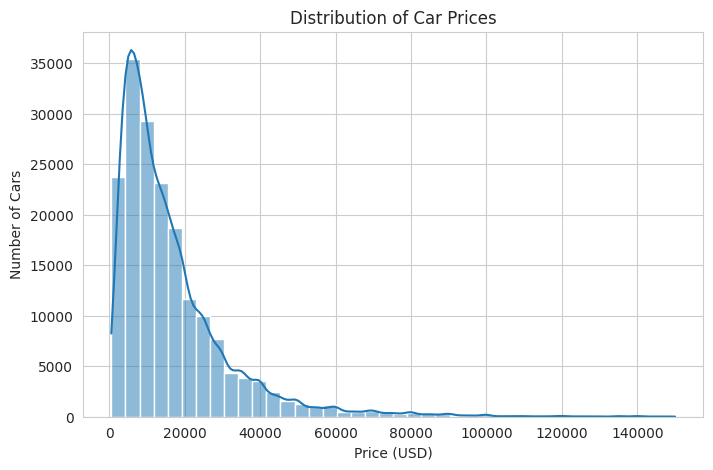

In [136]:
plt.figure(figsize=(8,5)); sns.histplot(df[PRICE], bins=40, kde=True)
plt.title("Distribution of Car Prices"); plt.xlabel("Price (USD)"); plt.ylabel("Number of Cars")
plt.savefig("chart1.png", dpi=150, bbox_inches="tight"); plt.show()

Observation: Prices are right-skewed. The mean ($16,537) is higher than the median ($11,995), with a skewness of 2.58, because a small number of expensive cars pull the average up.

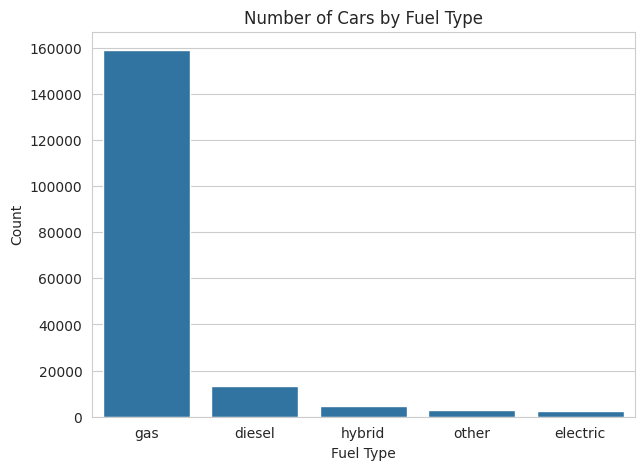

In [137]:
plt.figure(figsize=(7,5)); sns.countplot(data=df, x=FUEL, order=df[FUEL].value_counts().index)
plt.title("Number of Cars by Fuel Type"); plt.xlabel("Fuel Type"); plt.ylabel("Count")
plt.savefig("chart2.png", dpi=150, bbox_inches="tight"); plt.show()

In [138]:
(df[FUEL].value_counts(normalize=True) * 100).round(1)

,proportion
fuel,
gas,86.9
diesel,7.4
hybrid,2.6
other,1.7
electric,1.4


Observation: Gas is by far the most common fuel at 159,015 cars, about 86.9% of the cleaned data. Diesel is a distant second at roughly 7%, and hybrid, other and electric are each small.

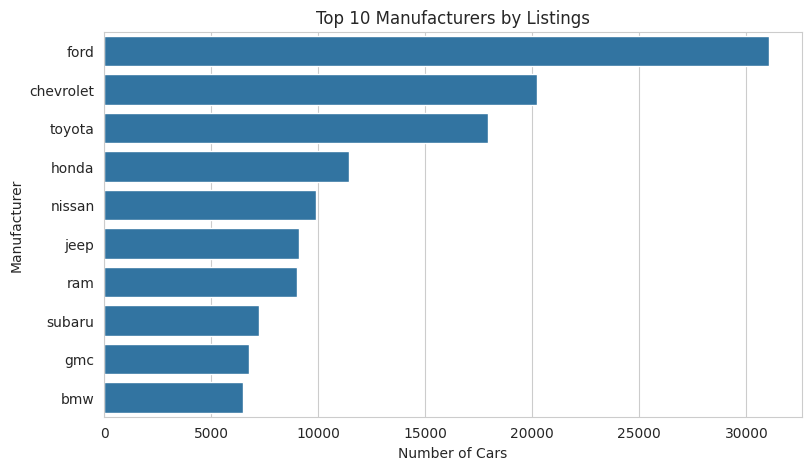

In [139]:
top_brands = df[BRAND].value_counts().head(10)
plt.figure(figsize=(9,5)); sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("Top 10 Manufacturers by Listings"); plt.xlabel("Number of Cars"); plt.ylabel("Manufacturer")
plt.savefig("chart3.png", dpi=150, bbox_inches="tight"); plt.show()

Observation: Ford has the most listings (31,038, about 17% of the data), followed by Chevrolet and Toyota. These three together make up roughly 38% of all listings. The dataset has 40 manufacturers in total.

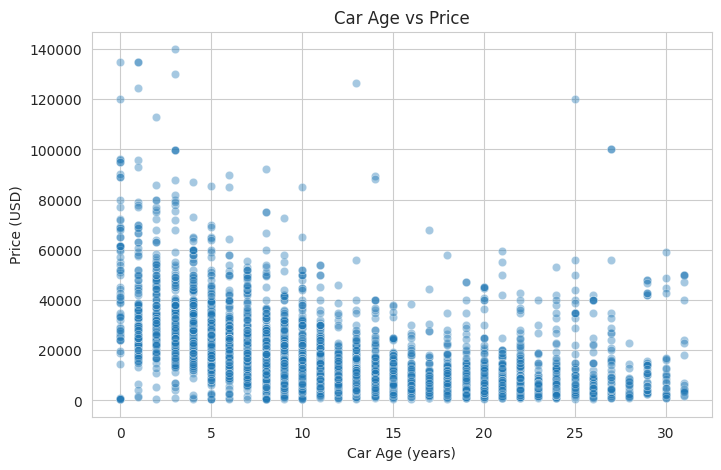

In [140]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=df.sample(5000, random_state=1), x="car_age", y=PRICE, alpha=0.4)
plt.title("Car Age vs Price"); plt.xlabel("Car Age (years)"); plt.ylabel("Price (USD)")
plt.savefig("chart4.png", dpi=150, bbox_inches="tight"); plt.show()

In [141]:
df["car_age"].corr(df[PRICE]).round(2)

np.float64(-0.45)

Observation: Older cars tend to cost less (correlation -0.45), but prices vary widely at every age, so age alone does not explain price.

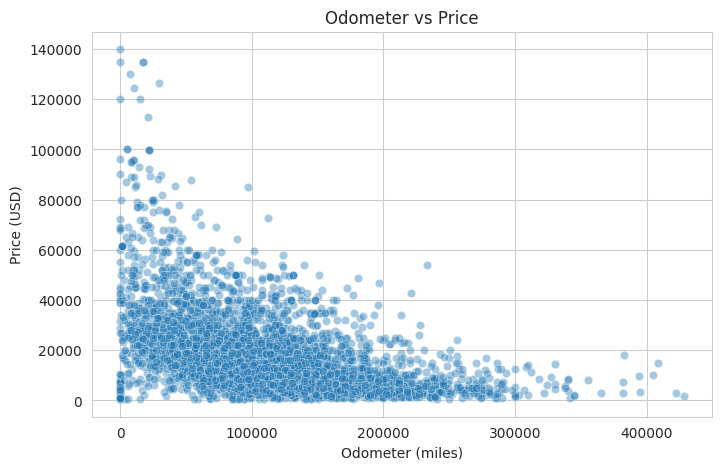

In [142]:
plt.figure(figsize=(8,5)); sns.scatterplot(data=df.sample(5000, random_state=1), x=KM, y=PRICE, alpha=0.4)
plt.title("Odometer vs Price"); plt.xlabel("Odometer (miles)"); plt.ylabel("Price (USD)")
plt.savefig("chart5.png", dpi=150, bbox_inches="tight"); plt.show()

Observation: Higher-mileage cars tend to be cheaper. The correlation between odometer and price is -0.52, the strongest link with price in this data.

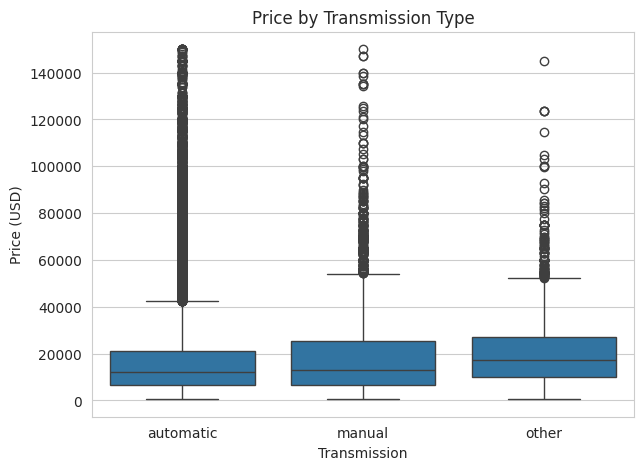

In [143]:
plt.figure(figsize=(7,5)); sns.boxplot(data=df, x=TRANS, y=PRICE)
plt.title("Price by Transmission Type"); plt.xlabel("Transmission"); plt.ylabel("Price (USD)")
plt.savefig("chart6.png", dpi=150, bbox_inches="tight"); plt.show()

In [144]:
df.groupby(TRANS)[PRICE].median()

,price
transmission,
automatic,11995.0
manual,12900.0
other,17422.5


Observation: Automatic cars are about 93.3% of listings. Median prices are $11,995 for automatic, $12,900 for manual and $17,422 for "other". This is an association only, and the data cannot say why.

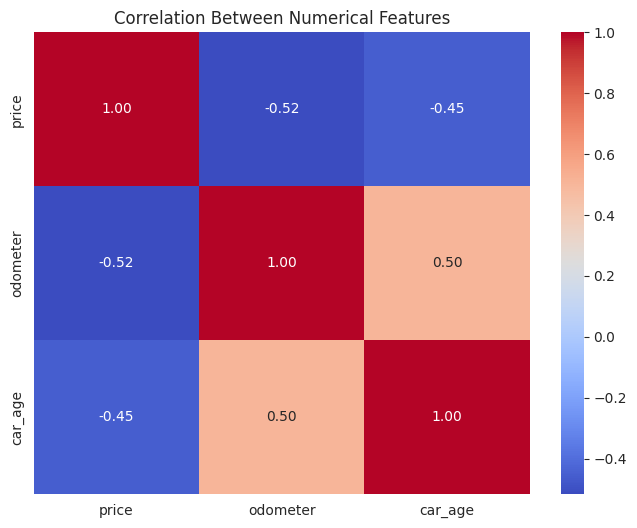

In [145]:
plt.figure(figsize=(8,6)); sns.heatmap(df[numerical_cols].drop(columns=[YEAR]).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features"); plt.savefig("chart7.png", dpi=150, bbox_inches="tight"); plt.show()

Observation: Odometer (-0.52) and car age (-0.45) have the strongest links with price. Age and mileage are also related (0.50), so their effects overlap.

In [146]:
df.groupby(BRAND)[PRICE].mean().sort_values(ascending=False).head(10)

,price
manufacturer,
ferrari,110732.500000
aston-martin,61541.055556
porsche,35554.201354
rover,28499.755623
tesla,26886.171763
ram,25873.782008
gmc,23882.752931
mercedes-benz,19655.213766
ford,19423.372769


## 6. Outliers

In [147]:
Q1, Q3 = df[PRICE].quantile(0.25), df[PRICE].quantile(0.75)
IQR = Q3 - Q1

In [148]:
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = df[(df[PRICE] < lower) | (df[PRICE] > upper)]

In [149]:
print(len(outliers), round(len(outliers)/len(df)*100, 2))
outliers.head(10)

10730 5.87


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,car_age
25,53900.0,2013,porsche,boxster s,excellent,6 cylinders,gas,38172.0,clean,automatic,rwd,convertible,yellow,ca,13
28,58500.0,2019,ford,f250,excellent,8 cylinders,diesel,50116.0,clean,automatic,4wd,pickup,black,ca,7
53,76000.0,2016,porsche,911 turbo/turbo s rs,excellent,6 cylinders,gas,40292.0,clean,automatic,NaN,other,NaN,ca,10
59,62500.0,2024,bmw,x7 x drive40i,excellent,6 cylinders,gas,22800.0,clean,automatic,4wd,SUV,grey,ca,2
89,44995.0,2022,toyota,4runner trd offroad prem,good,6 cylinders,gas,55985.0,clean,automatic,4wd,SUV,grey,ca,4
147,86998.0,2023,bmw,m8 competition,excellent,8 cylinders,gas,8568.0,clean,automatic,NaN,coupe,NaN,ca,3
151,68998.0,2024,bmw,i7,NaN,NaN,electric,22691.0,clean,automatic,4wd,sedan,NaN,ca,2
156,49999.0,2016,ford,f-650,good,10 cylinders,gas,141000.0,clean,automatic,rwd,truck,white,ca,10
157,94999.0,2024,ford,f550,good,8 cylinders,diesel,311.0,clean,automatic,NaN,truck,white,ca,2
162,54900.0,2025,acura,mdx advance sh-awd,like new,6 cylinders,gas,5350.0,clean,automatic,NaN,SUV,grey,ca,1


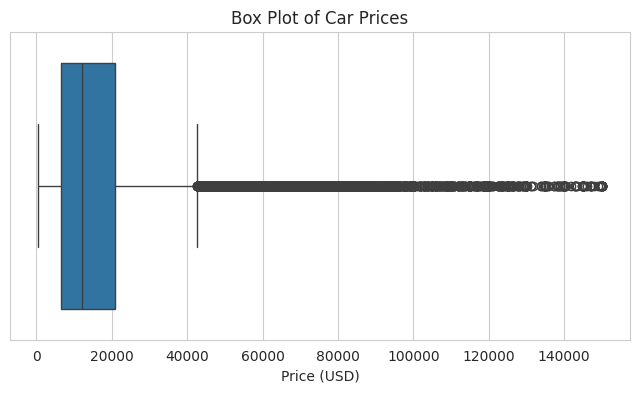

In [150]:
plt.figure(figsize=(8,4)); sns.boxplot(x=df[PRICE])
plt.title("Box Plot of Car Prices"); plt.xlabel("Price (USD)")
plt.savefig("chart8.png", dpi=150, bbox_inches="tight"); plt.show()

Observation: A small number of high-priced cars sit far above the rest. These were kept, because they are realistic listings (prices were capped at $150,000) and they explain why the mean is higher than the median.

## 7. Key Findings
1. Gas cars dominate the listings. Gas makes up about 86.9% of cars, so conclusions about diesel, hybrid and electric cars rest on far fewer records. (Chart 2)
2. Prices are right-skewed. The mean ($16,537) is higher than the median ($11,995), with a skewness of 2.58, because a small number of expensive cars pull the average up. (Chart 1)
3. Mileage has the strongest link with price. The correlation between odometer and price is -0.52, so higher-mileage cars tend to be cheaper. (Charts 5 and 7)
4. Older cars tend to cost less, but age alone is not enough. The correlation between car age and price is -0.45, and prices vary widely at every age. Age and mileage are also related (0.50), so their effects overlap. (Charts 4 and 7)
5. Automatic transmission is the norm, and median prices differ by type. Automatic cars are about 93.3% of listings. Median prices are $11,995 for automatic, $12,900 for manual and $17,422 for "other". This is an association only, and the data cannot say why. (Chart 6)
6. Ford, Chevrolet and Toyota are the most listed manufacturers. (Chart 3)

## 8. Limitations and Conclusion
Limitations
- The data comes from online listings, so asking prices may differ from actual sale prices.
- condition, cylinders, paint_color and drive have many missing values, so they were not used in the main analysis.
- Some removed duplicates may have been different cars with identical details, since ID, URL and VIN columns were dropped first.
- The data is US-only (prices in USD, mileage in miles) and does not show where each car was sold within the country beyond the state column.
- Results show associations, not causes.

Conclusion
This EDA cleaned a US used-car listings dataset from 295,451 to 182,894 rows and found that mileage and age are the main numeric factors linked to lower prices. Prices are right-skewed, and gas-powered automatic cars from Ford, Chevrolet and Toyota dominate the listings. The main challenges were converting text columns to numbers, removing duplicates and unrealistic values, and deciding to keep high-priced outliers. Future work could compare prices by state or build a price prediction model.